# E-commerce Sales and Customer Behavior Analysis

## Project Overview

This project analyzes Brazilian e-commerce data from Olist to identify sales trends, customer purchasing behavior, product performance, and customer satisfaction.

## Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook
- MySQL
- Excel

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
data_path = "../data/raw"

print("Dataset folder path:", data_path)
print("Files found:", os.listdir(data_path))

Dataset folder path: ../data/raw


FileNotFoundError: [WinError 3] The system cannot find the path specified: '../data/raw'

In [5]:
import os

print(os.getcwd())

C:\Users\Hp\Downloads\ecommerce-sales-customer-behavior-analysis


In [6]:
data_path = "data/raw"

print("Files found:")
print(os.listdir(data_path))

Files found:
['archive (2).zip']


In [7]:
print(os.listdir("data/raw"))

['archive (2).zip']


In [9]:
print(os.listdir("data/raw"))

['archive (2).zip', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [10]:
# Load all nine CSV files

customers = pd.read_csv("data/raw/olist_customers_dataset.csv")
geolocation = pd.read_csv("data/raw/olist_geolocation_dataset.csv")
orders = pd.read_csv("data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("data/raw/olist_order_reviews_dataset.csv")
products = pd.read_csv("data/raw/olist_products_dataset.csv")
sellers = pd.read_csv("data/raw/olist_sellers_dataset.csv")
category_translation = pd.read_csv("data/raw/product_category_name_translation.csv")

print("All nine datasets loaded successfully!")

All nine datasets loaded successfully!


In [11]:
# Check the shape of all datasets

datasets = {
    "Customers": customers,
    "Geolocation": geolocation,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Customers: 99441 rows, 5 columns
Geolocation: 1000163 rows, 5 columns
Orders: 99441 rows, 8 columns
Order Items: 112650 rows, 7 columns
Payments: 103886 rows, 5 columns
Reviews: 99224 rows, 7 columns
Products: 32951 rows, 9 columns
Sellers: 3095 rows, 4 columns
Category Translation: 71 rows, 2 columns


In [12]:
# Display column names and data types

for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print(df.dtypes)


Customers
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Geolocation
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Orders
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Order Items
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

Payments
order_id   

In [13]:
# Check missing values in all datasets

for name, df in datasets.items():
    print("\n", "=" * 40)
    print(name)
    print("=" * 40)
    print(df.isnull().sum())


Customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Geolocation
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order Items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Payments
order_id                0
payment_sequential      0
payment_type            0
payment_installments 

In [14]:
# Check the number of orders by status

print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [15]:
# Convert order date columns into datetime format

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

print("Order date columns converted successfully!")

print(orders[date_columns].dtypes)

Order date columns converted successfully!
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [16]:
# Check missing dates after conversion

print(orders[date_columns].isnull().sum())

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [17]:
# Fill missing product categories

products["product_category_name"] = (
    products["product_category_name"].fillna("Unknown")
)

print("Missing product categories after cleaning:",
      products["product_category_name"].isnull().sum())

Missing product categories after cleaning: 0


In [18]:
# Fill missing numerical product measurements with column means

measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for column in measurement_columns:
    products[column] = products[column].fillna(
        products[column].mean()
    )

print("Missing product measurements after cleaning:")
print(products[measurement_columns].isnull().sum())

Missing product measurements after cleaning:
product_weight_g     0
product_length_cm    0
product_height_cm    0
product_width_cm     0
dtype: int64


In [19]:
# Fill missing customer review comments

reviews["review_comment_title"] = (
    reviews["review_comment_title"].fillna("No comment")
)

reviews["review_comment_message"] = (
    reviews["review_comment_message"].fillna("No comment")
)

print("Missing review values after cleaning:")
print(reviews[[
    "review_comment_title",
    "review_comment_message"
]].isnull().sum())

Missing review values after cleaning:
review_comment_title      0
review_comment_message    0
dtype: int64


In [20]:
# Save cleaned datasets

os.makedirs("data/processed", exist_ok=True)

customers.to_csv("data/processed/customers_cleaned.csv", index=False)
orders.to_csv("data/processed/orders_cleaned.csv", index=False)
order_items.to_csv("data/processed/order_items_cleaned.csv", index=False)
payments.to_csv("data/processed/payments_cleaned.csv", index=False)
reviews.to_csv("data/processed/reviews_cleaned.csv", index=False)
products.to_csv("data/processed/products_cleaned.csv", index=False)
sellers.to_csv("data/processed/sellers_cleaned.csv", index=False)
geolocation.to_csv("data/processed/geolocation_cleaned.csv", index=False)
category_translation.to_csv("data/processed/category_translation_cleaned.csv", index=False)

print("All nine cleaned datasets saved successfully!")

All nine cleaned datasets saved successfully!


In [21]:
# Verify saved cleaned datasets

processed_files = os.listdir("data/processed")

print("Saved files:")
for file in processed_files:
    print(file)

print("\nTotal files saved:", len(processed_files))

Saved files:
category_translation_cleaned.csv
customers_cleaned.csv
geolocation_cleaned.csv
orders_cleaned.csv
order_items_cleaned.csv
payments_cleaned.csv
products_cleaned.csv
reviews_cleaned.csv
sellers_cleaned.csv

Total files saved: 9


In [22]:
# Check duplicate records in all nine datasets

for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

Customers: 0 duplicate rows
Geolocation: 261831 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Payments: 0 duplicate rows
Reviews: 0 duplicate rows
Products: 0 duplicate rows
Sellers: 0 duplicate rows
Category Translation: 0 duplicate rows


In [23]:
# Display the first 10 duplicate geolocation records

geolocation_duplicates = geolocation[
    geolocation.duplicated(keep=False)
]

geolocation_duplicates.head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [24]:
# Remove exact duplicate rows from geolocation

geolocation = geolocation.drop_duplicates()

print("Geolocation records after removing duplicates:",
      len(geolocation))

print("Remaining duplicate rows:",
      geolocation.duplicated().sum())

Geolocation records after removing duplicates: 738332
Remaining duplicate rows: 0


In [25]:
geolocation.to_csv(
    "data/processed/geolocation_cleaned.csv",
    index=False
)

print("Corrected geolocation dataset saved successfully!")

Corrected geolocation dataset saved successfully!


In [26]:
# Check duplicate identifiers

print("Duplicate Order IDs:", orders["order_id"].duplicated().sum())

print("Duplicate Customer IDs:", customers["customer_id"].duplicated().sum())

print("Duplicate Product IDs:", products["product_id"].duplicated().sum())

print("Duplicate Seller IDs:", sellers["seller_id"].duplicated().sum())

Duplicate Order IDs: 0
Duplicate Customer IDs: 0
Duplicate Product IDs: 0
Duplicate Seller IDs: 0


In [27]:
# Final missing-value check

for name, df in datasets.items():
    total_missing = df.isnull().sum().sum()
    print(f"{name}: {total_missing} missing values")

Customers: 0 missing values
Geolocation: 0 missing values
Orders: 4908 missing values
Order Items: 0 missing values
Payments: 0 missing values
Reviews: 0 missing values
Products: 1830 missing values
Sellers: 0 missing values
Category Translation: 0 missing values


In [28]:
# Save final cleaned datasets

for name, df in datasets.items():
    df.to_csv(
        f"data/processed/{name.lower().replace(' ', '_')}_cleaned.csv",
        index=False
    )

print("All cleaned datasets updated successfully!")

All cleaned datasets updated successfully!


In [29]:
# Select delivered orders
delivered_order_ids = orders.loc[
    orders["order_status"] == "delivered",
    "order_id"
]

# Select items belonging to delivered orders
delivered_items = order_items[
    order_items["order_id"].isin(delivered_order_ids)
]

# Calculate business KPIs
total_revenue = delivered_items["price"].sum()
total_orders = delivered_order_ids.nunique()

# Display results
print(f"Total Sales Revenue: R$ {total_revenue:,.2f}")
print(f"Total Delivered Orders: {total_orders:,}")

Total Sales Revenue: R$ 13,221,498.11
Total Delivered Orders: 96,478


In [30]:
# Calculate Average Order Value
average_order_value = total_revenue / total_orders

print(f"Average Order Value: R$ {average_order_value:,.2f}")

Average Order Value: R$ 137.04


In [31]:
# Calculate total unique customers
total_customers = customers["customer_unique_id"].nunique()

print(f"Total Unique Customers: {total_customers:,}")

Total Unique Customers: 96,096


In [32]:
# Count delivered orders per unique customer
customer_orders = orders[
    orders["order_status"] == "delivered"
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id"
)

orders_per_customer = customer_orders.groupby(
    "customer_unique_id"
)["order_id"].nunique()

# Count repeat customers
repeat_customers = (orders_per_customer >= 2).sum()

print(f"Repeat Customers: {repeat_customers:,}")

Repeat Customers: 2,801


In [33]:
# Calculate repeat customer rate
repeat_customer_rate = (
    repeat_customers / total_customers
) * 100

print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")

Repeat Customer Rate: 2.91%


In [34]:
# Calculate average review score
average_review_score = reviews["review_score"].mean()

print(f"Average Review Score: {average_review_score:.2f} / 5")

Average Review Score: 4.09 / 5


In [35]:
# Calculate delivery time in days

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["delivery_time_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

average_delivery_time = delivered_orders[
    "delivery_time_days"
].mean()

print(f"Average Delivery Time: {average_delivery_time:.2f} days")

Average Delivery Time: 12.56 days


## Key Business Performance Indicators (KPIs)

1. Total Sales Revenue: R$ 13,221,498.11
2. Total Delivered Orders: 96,478
3. Average Order Value: R$ 137.04
4. Total Unique Customers: 96,096
5. Repeat Customers: 2,801
6. Repeat Customer Rate: 2.91%
7. Average Review Score: 4.09 / 5
8. Average Delivery Time: 12.56 days

In [36]:
# Merge delivered order items with purchase dates
monthly_sales = delivered_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

# Extract purchase month
monthly_sales["month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly revenue
monthly_revenue = (
    monthly_sales.groupby("month")["price"]
    .sum()
    .reset_index()
)

# Format month for display
monthly_revenue["month"] = monthly_revenue["month"].astype(str)

# Display monthly revenue
print(monthly_revenue.to_string(index=False))

  month     price
2016-09    134.97
2016-10  40325.11
2016-12     10.90
2017-01 111798.36
2017-02 234223.40
2017-03 359198.85
2017-04 340669.68
2017-05 489338.25
2017-06 421923.37
2017-07 481604.52
2017-08 554699.70
2017-09 607399.67
2017-10 648247.65
2017-11 987765.37
2017-12 726033.19
2018-01 924645.00
2018-02 826437.13
2018-03 953356.25
2018-04 973534.09
2018-05 977544.69
2018-06 856077.86
2018-07 867953.46
2018-08 838576.64


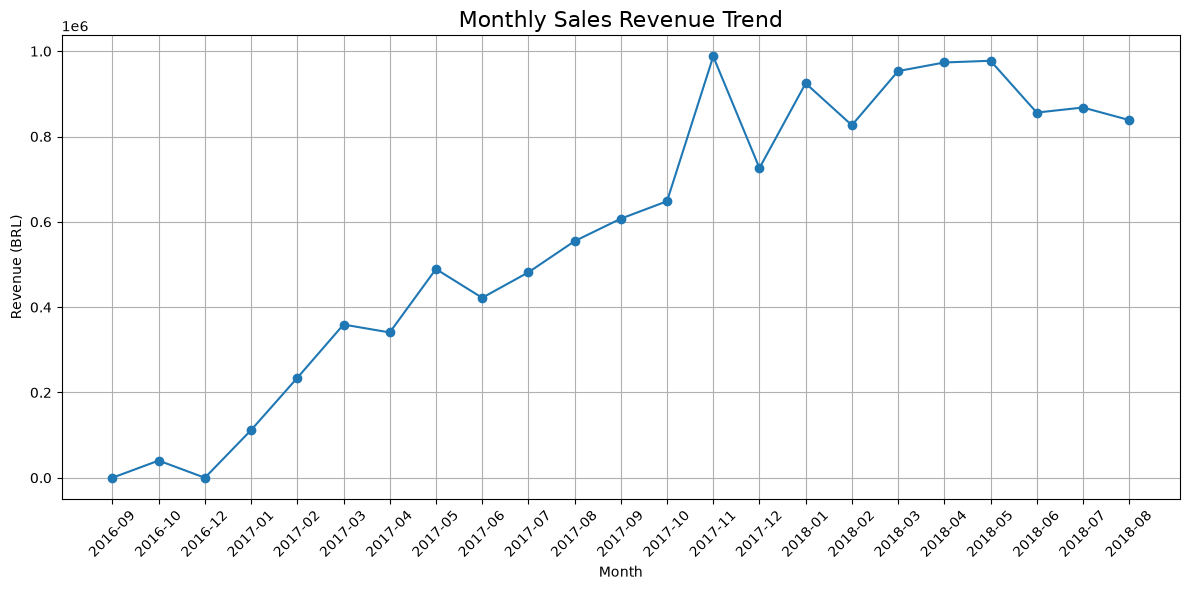

Monthly revenue chart saved successfully!


In [37]:
# Create monthly revenue trend chart

os.makedirs("visualizations", exist_ok=True)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["price"],
    marker="o"
)

plt.title("Monthly Sales Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()

# Save chart
plt.savefig(
    "visualizations/01_monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly revenue chart saved successfully!")

In [38]:
# Identify highest and lowest revenue months

highest_month = monthly_revenue.loc[
    monthly_revenue["price"].idxmax()
]

lowest_month = monthly_revenue.loc[
    monthly_revenue["price"].idxmin()
]

print("Highest Revenue Month:")
print(highest_month)

print("\nLowest Revenue Month:")
print(lowest_month)

Highest Revenue Month:
month      2017-11
price    987765.37
Name: 13, dtype: object

Lowest Revenue Month:
month    2016-12
price       10.9
Name: 2, dtype: object


## Monthly Sales Revenue Analysis

- Highest revenue month: November 2017 (R$ 987,765.37).
- Lowest revenue month: December 2016 (R$ 10.90).
- Sales revenue increased considerably throughout 2017.
- Revenue remained strong during 2018.
- The unusually low revenue in early dataset months should be considered when interpreting the trend.

In [39]:
# Prepare product category sales analysis

category_sales = delivered_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Use English category names
category_sales["product_category_name_english"] = (
    category_sales["product_category_name_english"]
    .fillna("Unknown")
)

# Calculate revenue by category
category_revenue = (
    category_sales.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(category_revenue.head(10).to_string(index=False))

product_category_name_english      price
                health_beauty 1233131.72
                watches_gifts 1166176.98
               bed_bath_table 1023434.76
               sports_leisure  954852.55
        computers_accessories  888724.61
              furniture_decor  711927.69
                   housewares  615628.69
                   cool_stuff  610204.10
                         auto  578966.65
                         toys  471286.48


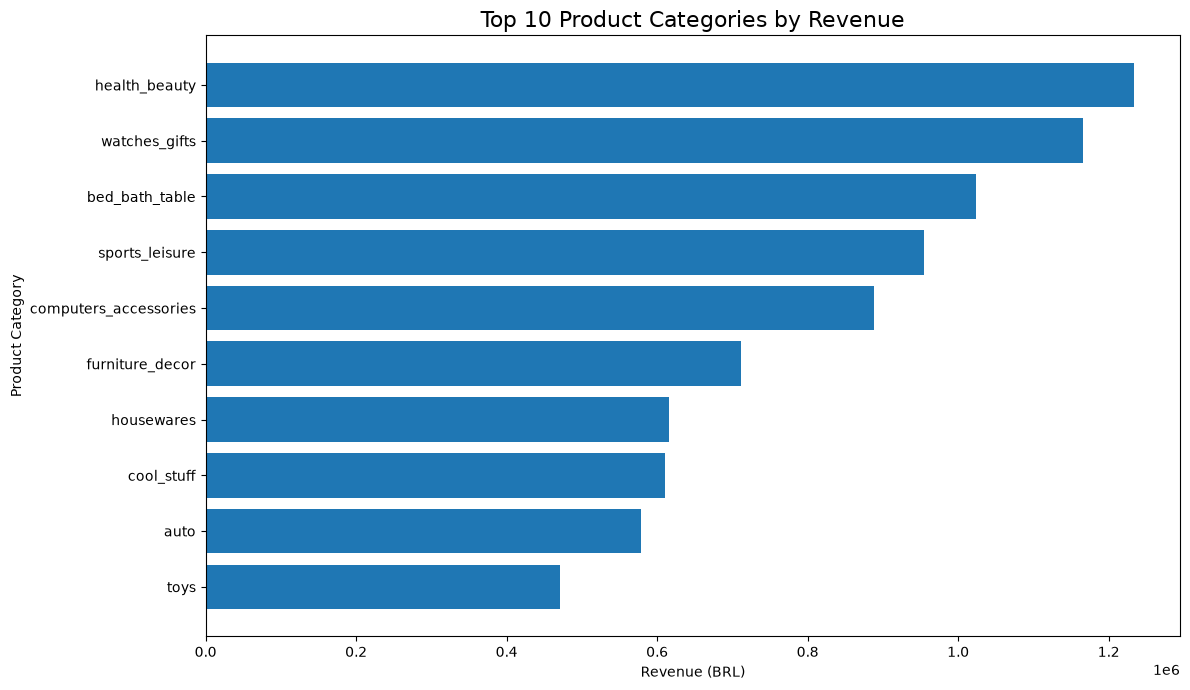

Top 10 category chart saved successfully!


In [40]:
# Create top 10 category revenue chart

top_10_categories = category_revenue.head(10).sort_values(
    "price",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["product_category_name_english"],
    top_10_categories["price"]
)

plt.title("Top 10 Product Categories by Revenue", fontsize=16)
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()

# Save chart
plt.savefig(
    "visualizations/02_top_10_categories_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Top 10 category chart saved successfully!")

In [41]:
# Identify highest and lowest revenue categories

highest_category = category_revenue.iloc[0]
lowest_category = category_revenue.iloc[-1]

print("Highest Revenue Category:")
print(highest_category)

print("\nLowest Revenue Category:")
print(lowest_category)

Highest Revenue Category:
product_category_name_english    health_beauty
price                               1233131.72
Name: 0, dtype: object

Lowest Revenue Category:
product_category_name_english    security_and_services
price                                           283.29
Name: 71, dtype: object


## Product Category Revenue Analysis

- Highest revenue category: Health & Beauty (R$ 1,233,131.72).
- Second highest: Watches & Gifts (R$ 1,166,176.98).
- Third highest: Bed, Bath & Table (R$ 1,023,434.76).
- Lowest revenue category: Security & Services (R$ 283.29).
- Health & Beauty is the leading revenue-generating product category.
- Product category performance varies considerably across the marketplace.

In [42]:
# Merge delivered items with customer information

state_sales = delivered_items.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

state_sales = state_sales.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Calculate revenue by state
state_revenue = (
    state_sales.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Display top 10 states
print(state_revenue.head(10).to_string(index=False))

customer_state      price
            SP 5067633.16
            RJ 1759651.13
            MG 1552481.83
            RS  728897.47
            PR  666063.51
            SC  507012.13
            BA  493584.14
            DF  296498.41
            GO  282836.70
            ES  268643.45


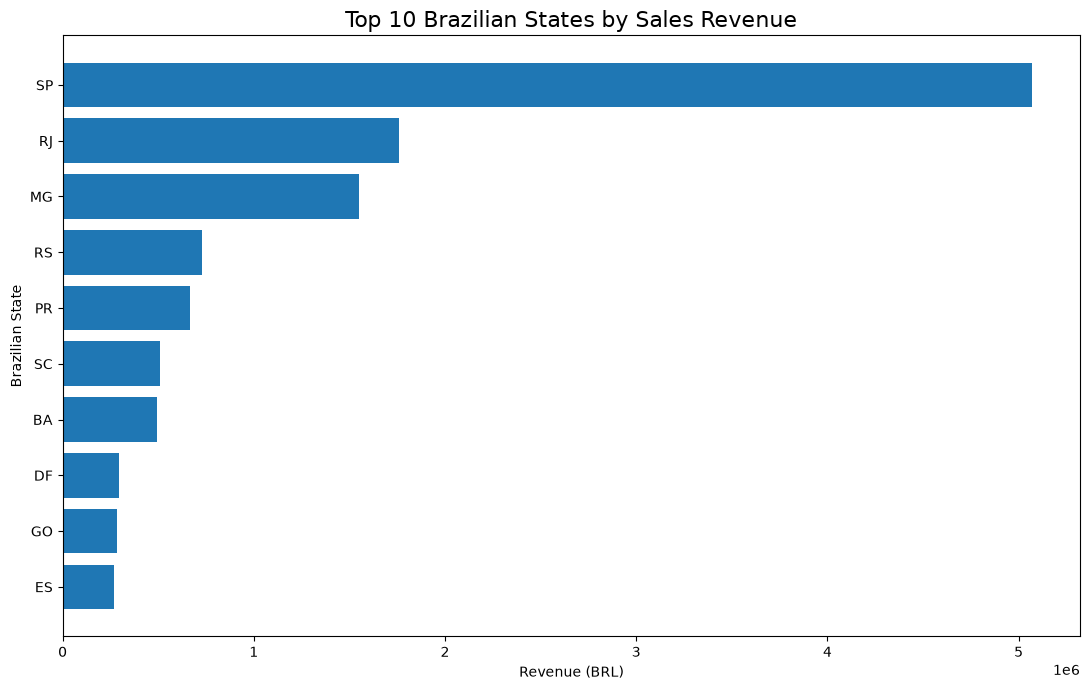

State revenue chart saved successfully!


In [43]:
# Create top 10 states revenue chart

top_10_states = state_revenue.head(10).sort_values(
    "price",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_10_states["customer_state"],
    top_10_states["price"]
)

plt.title("Top 10 Brazilian States by Sales Revenue", fontsize=16)
plt.xlabel("Revenue (BRL)")
plt.ylabel("Brazilian State")

plt.tight_layout()

# Save chart
plt.savefig(
    "visualizations/03_top_10_states_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("State revenue chart saved successfully!")

In [44]:
# Identify highest and lowest revenue states

highest_state = state_revenue.iloc[0]
lowest_state = state_revenue.iloc[-1]

print("Highest Revenue State:")
print(highest_state)

print("\nLowest Revenue State:")
print(lowest_state)

Highest Revenue State:
customer_state            SP
price             5067633.16
Name: 0, dtype: object

Lowest Revenue State:
customer_state         RR
price             7057.47
Name: 26, dtype: object


## Geographical Sales Analysis

- Highest revenue state: São Paulo (SP) — R$ 5,067,633.16.
- Second highest: Rio de Janeiro (RJ) — R$ 1,759,651.13.
- Third highest: Minas Gerais (MG) — R$ 1,552,481.83.
- Lowest revenue state: Roraima (RR) — R$ 7,057.47.
- São Paulo is the leading regional market in the Olist dataset.
- Sales revenue varies considerably across Brazilian states.

In [45]:
# Filter payments for delivered orders

delivered_payments = payments[
    payments["order_id"].isin(delivered_order_ids)
]

# Analyze payment methods
payment_analysis = (
    delivered_payments.groupby("payment_type")
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_records=("payment_type", "size"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_payment_value", ascending=False)
    .reset_index()
)

print(payment_analysis.to_string(index=False))

payment_type  total_payment_value  payment_records  unique_orders
 credit_card          12101094.88            74586          74304
      boleto           2769932.58            19191          19191
     voucher            343013.19             5493           3679
  debit_card            208421.12             1486           1485


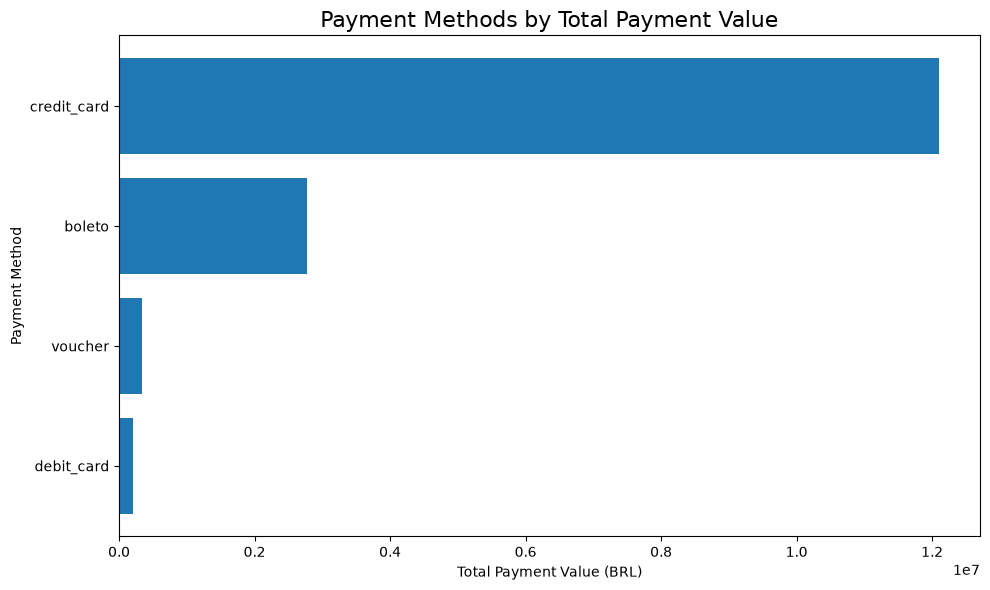

Payment methods chart saved successfully!


In [46]:
# Create payment methods chart

payment_chart = payment_analysis.sort_values(
    "total_payment_value",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    payment_chart["payment_type"],
    payment_chart["total_payment_value"]
)

plt.title("Payment Methods by Total Payment Value", fontsize=16)
plt.xlabel("Total Payment Value (BRL)")
plt.ylabel("Payment Method")

plt.tight_layout()

# Save chart
plt.savefig(
    "visualizations/04_payment_methods.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Payment methods chart saved successfully!")

In [47]:
# Identify highest and lowest payment methods

highest_payment = payment_analysis.iloc[0]
lowest_payment = payment_analysis.iloc[-1]

print("Highest Payment Method:")
print(highest_payment)

print("\nLowest Payment Method:")
print(lowest_payment)

Highest Payment Method:
payment_type           credit_card
total_payment_value    12101094.88
payment_records              74586
unique_orders                74304
Name: 0, dtype: object

Lowest Payment Method:
payment_type           debit_card
total_payment_value     208421.12
payment_records              1486
unique_orders                1485
Name: 3, dtype: object


## Payment Methods Analysis

- Credit cards were the leading payment method, accounting for 74,304 unique orders.
- Boleto was the second most popular payment method, with 19,191 unique orders.
- Debit cards were the least used payment method, with 1,485 unique orders.
- Credit cards generated the highest total payment value (R$ 12,101,094.88).
- Debit cards generated the lowest total payment value (R$ 208,421.12).
- Some orders had multiple payment records, particularly voucher payments.

**Business Insight:** Credit cards dominate customer payment activity in the Olist marketplace, indicating the importance of offering convenient card-payment options.

In [48]:
# Analyze customer review scores

review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = [
    "review_score",
    "number_of_reviews"
]

print(review_distribution.to_string(index=False))

 review_score  number_of_reviews
            1              11424
            2               3151
            3               8179
            4              19142
            5              57328


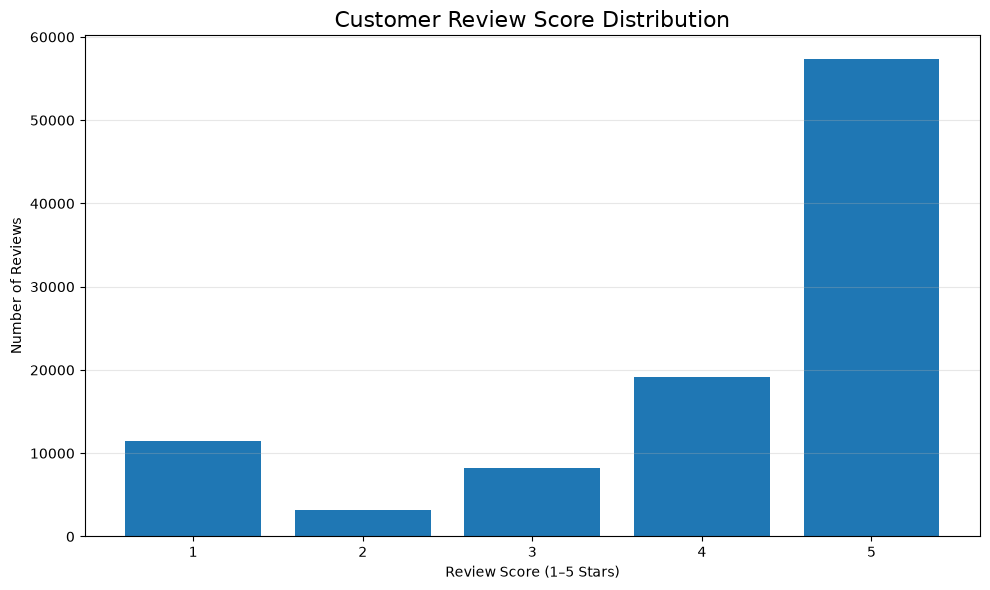

Customer review chart saved successfully!


In [49]:
# Customer Review Score Distribution

plt.figure(figsize=(10, 6))

plt.bar(
    review_distribution["review_score"],
    review_distribution["number_of_reviews"]
)

plt.title("Customer Review Score Distribution", fontsize=16)
plt.xlabel("Review Score (1–5 Stars)")
plt.ylabel("Number of Reviews")

plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "visualizations/05_review_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Customer review chart saved successfully!")

## Customer Satisfaction Analysis

- Total recorded reviews: 99,224.
- Five-star reviews were the most common, with 57,328 reviews.
- Four-star reviews accounted for 19,142 reviews.
- One-star reviews accounted for 11,424 reviews.
- Two-star reviews were the least common, with 3,151 reviews.
- The average customer review score was 4.09 out of 5.

**Business Insight:** The high proportion of five-star reviews indicates generally positive customer satisfaction. However, one-star reviews highlight opportunities to investigate service quality, delivery issues, and product expectations.

In [50]:
# Prepare delivered orders for delivery performance analysis

delivery_analysis = orders[
    orders["order_status"] == "delivered"
].copy()

delivery_analysis["delivery_difference_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

print("Delivery difference calculated successfully!")
print(delivery_analysis[
    ["order_id", "delivery_difference_days"]
].head())

Delivery difference calculated successfully!
                           order_id  delivery_difference_days
0  e481f51cbdc54678b7cc49136f2d6af7                 -7.107488
1  53cdb2fc8bc7dce0b6741e2150273451                 -5.355729
2  47770eb9100c2d0c44946d9cf07ec65d                -17.245498
3  949d5b44dbf5de918fe9c16f97b45f8a                -12.980069
4  ad21c59c0840e6cb83a9ceb5573f8159                 -9.238171


In [51]:
# Classify delivery performance

delivery_analysis["delivery_status"] = np.where(
    delivery_analysis["delivery_difference_days"] < 0,
    "Early",
    np.where(
        delivery_analysis["delivery_difference_days"] > 0,
        "Late",
        "On Time"
    )
)

delivery_summary = (
    delivery_analysis["delivery_status"]
    .value_counts()
    .reset_index()
)

delivery_summary.columns = [
    "delivery_status",
    "number_of_orders"
]

print(delivery_summary.to_string(index=False))

delivery_status  number_of_orders
          Early             88644
           Late              7826
        On Time                 8


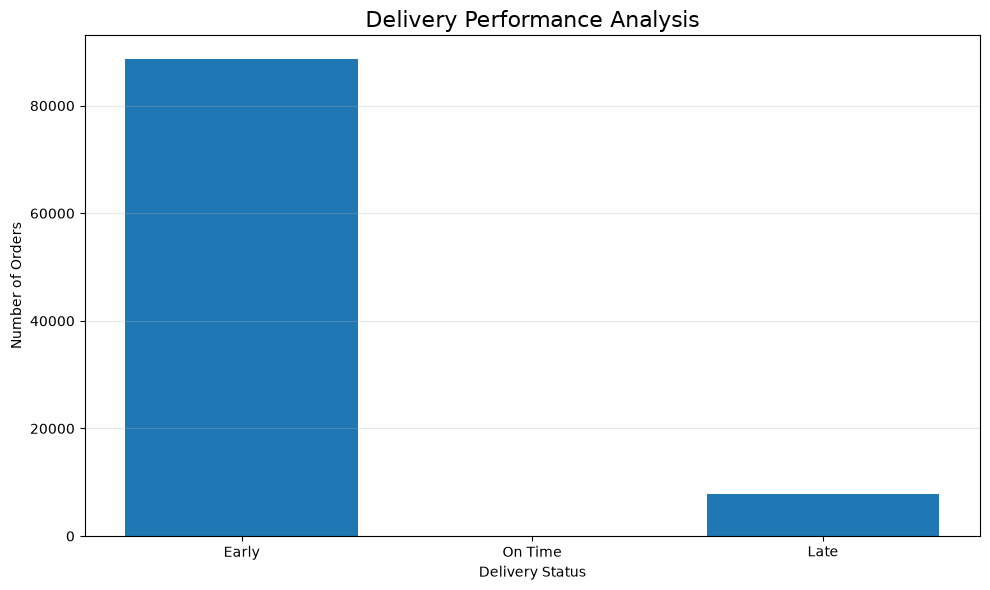

Delivery performance chart saved successfully!


In [52]:
# Delivery Performance Analysis

delivery_chart = delivery_summary.set_index(
    "delivery_status"
).reindex(["Early", "On Time", "Late"]).reset_index()

plt.figure(figsize=(10, 6))

plt.bar(
    delivery_chart["delivery_status"],
    delivery_chart["number_of_orders"]
)

plt.title("Delivery Performance Analysis", fontsize=16)
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/06_delivery_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Delivery performance chart saved successfully!")

## Delivery Performance Analysis

- Total delivered orders analyzed: 96,478.
- Orders delivered early: 88,644 (91.88%).
- Orders delivered late: 7,826 (8.11%).
- Orders delivered exactly on time: 8 (0.01%).
- Most orders arrived before their estimated delivery dates.

**Business Insight:** Olist demonstrated strong delivery performance, with approximately 92% of delivered orders arriving earlier than expected. However, late deliveries represent an opportunity to improve logistics and customer experience.

In [53]:
# Verify saved visualization files

visualization_files = os.listdir("visualizations")

for file in sorted(visualization_files):
    print(file)

01_monthly_revenue_trend.png
02_top_10_categories_revenue.png
03_top_10_states_revenue.png
04_payment_methods.png
05_review_score_distribution.png
06_delivery_performance.png


In [54]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\Hp\Downloads\ecommerce-sales-customer-behavior-analysis


In [55]:
import os

for root, folders, files in os.walk(os.getcwd()):
    for file in files:
        if file.endswith(".ipynb"):
            path = os.path.join(root, file)
            print("Notebook found:", path)

Notebook found: C:\Users\Hp\Downloads\ecommerce-sales-customer-behavior-analysis\ecommerce_sales_analysis.ipynb.ipynb
Notebook found: C:\Users\Hp\Downloads\ecommerce-sales-customer-behavior-analysis\.ipynb_checkpoints\ecommerce_sales_analysis.ipynb-checkpoint.ipynb


In [1]:
# Prepare monthly sales revenue

sales_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="inner"
)

sales_data = sales_data[
    sales_data["order_status"] == "delivered"
].copy()

sales_data["month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_revenue = (
    sales_data.groupby("month")["price"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = monthly_revenue["month"].astype(str)

monthly_revenue.rename(
    columns={"price": "total_revenue"},
    inplace=True
)

monthly_revenue["total_revenue"] = (
    monthly_revenue["total_revenue"].round(2)
)

monthly_revenue.to_csv(
    "excel/monthly_sales_revenue.csv",
    index=False
)

monthly_revenue.head()

NameError: name 'order_items' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

orders = pd.read_csv(
    "data/processed/orders_cleaned.csv"
)

order_items = pd.read_csv(
    "data/processed/order_items_cleaned.csv"
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print("Orders loaded:", orders.shape)
print("Order items loaded:", order_items.shape)

Orders loaded: (99441, 8)
Order items loaded: (112650, 7)


In [3]:
# Prepare monthly sales revenue

sales_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="inner"
)

sales_data = sales_data[
    sales_data["order_status"] == "delivered"
].copy()

sales_data["month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_revenue = (
    sales_data.groupby("month")["price"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = monthly_revenue["month"].astype(str)

monthly_revenue.rename(
    columns={"price": "total_revenue"},
    inplace=True
)

monthly_revenue["total_revenue"] = (
    monthly_revenue["total_revenue"].round(2)
)

monthly_revenue.to_csv(
    "excel/monthly_sales_revenue.csv",
    index=False
)

print("Monthly sales file saved successfully!")
display(monthly_revenue.head())

Monthly sales file saved successfully!


C:\Users\Hp\AppData\Local\Temp\ipykernel_18184\2722806009.py:25: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  monthly_revenue.rename(


,month,total_revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40


In [4]:
# Prepare product category revenue

products = pd.read_csv(
    "data/processed/products_cleaned.csv"
)

category_translation = pd.read_csv(
    "data/processed/category_translation_cleaned.csv"
)

category_sales = (
    order_items.merge(
        orders[["order_id", "order_status"]],
        on="order_id",
        how="inner"
    )
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="inner"
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left"
    )
)

category_sales = category_sales[
    category_sales["order_status"] == "delivered"
].copy()

category_sales["category"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"])
    .fillna("Unknown")
)

category_revenue = (
    category_sales.groupby("category")["price"]
    .sum()
    .reset_index()
    .sort_values("price", ascending=False)
    .head(10)
)

category_revenue["price"] = category_revenue["price"].round(2)

category_revenue.rename(
    columns={
        "category": "product_category",
        "price": "total_revenue"
    },
    inplace=True
)

category_revenue.to_csv(
    "excel/top_10_category_revenue.csv",
    index=False
)

print("Category revenue file saved successfully!")
display(category_revenue)

Category revenue file saved successfully!


C:\Users\Hp\AppData\Local\Temp\ipykernel_18184\919621064.py:49: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  category_revenue.rename(


,product_category,total_revenue
44,health_beauty,1233131.72
73,watches_gifts,1166176.98
8,bed_bath_table,1023434.76
68,sports_leisure,954852.55
16,computers_accessories,888724.61
40,furniture_decor,711927.69
50,housewares,615628.69
21,cool_stuff,610204.10
6,auto,578966.65
72,toys,471286.48


In [5]:
# Load customer reviews
reviews = pd.read_csv(
    "data/processed/reviews_cleaned.csv"
)

# Calculate review score distribution
review_distribution = (
    reviews.groupby("review_score")
    .size()
    .reset_index(name="number_of_reviews")
    .sort_values("review_score")
)

# Calculate percentage of reviews
review_distribution["percentage"] = (
    review_distribution["number_of_reviews"]
    / review_distribution["number_of_reviews"].sum()
    * 100
).round(2)

# Save Excel data
review_distribution.to_csv(
    "excel/review_score_distribution.csv",
    index=False
)

print("Review distribution file saved successfully!")
display(review_distribution)

Review distribution file saved successfully!


,review_score,number_of_reviews,percentage
0,1,11424,11.51
1,2,3151,3.18
2,3,8179,8.24
3,4,19142,19.29
4,5,57328,57.78


In [7]:
customers = pd.read_csv(
    "data/processed/customers_cleaned.csv"
)

print("Customers loaded:", customers.shape)

Customers loaded: (99441, 5)


In [8]:
# Prepare repeat customer analysis

customer_orders = orders[
    orders["order_status"] == "delivered"
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="inner"
)

orders_per_customer = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_customer_count = (orders_per_customer >= 2).sum()
one_time_customer_count = (orders_per_customer == 1).sum()

customer_type = pd.DataFrame({
    "customer_type": ["Repeat Customers", "One-Time Customers"],
    "number_of_customers": [
        repeat_customer_count,
        one_time_customer_count
    ]
})

customer_type.to_csv(
    "excel/customer_type_analysis.csv",
    index=False
)

print("Customer type file saved successfully!")
display(customer_type)

Customer type file saved successfully!


,customer_type,number_of_customers
0,Repeat Customers,2801
1,One-Time Customers,90557


In [9]:
# Load payment dataset
payments = pd.read_csv(
    "data/processed/payments_cleaned.csv"
)

# Select payments for delivered orders
delivered_payments = payments.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="inner"
)

delivered_payments = delivered_payments[
    delivered_payments["order_status"] == "delivered"
]

# Analyze payment methods
payment_analysis = (
    delivered_payments.groupby("payment_type")
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_records=("order_id", "size"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("total_payment_value", ascending=False)
)

payment_analysis["total_payment_value"] = (
    payment_analysis["total_payment_value"].round(2)
)

# Save the result
payment_analysis.to_csv(
    "excel/payment_method_analysis.csv",
    index=False
)

print("Payment analysis file saved successfully!")
display(payment_analysis)

Payment analysis file saved successfully!


,payment_type,total_payment_value,payment_records,unique_orders
1,credit_card,12101094.88,74586,74304
0,boleto,2769932.58,19191,19191
3,voucher,343013.19,5493,3679
2,debit_card,208421.12,1486,1485


In [10]:
# Prepare delivery performance analysis

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

delivery_data = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

delivery_data["delivery_status"] = np.select(
    [
        delivery_data["order_delivered_customer_date"]
        < delivery_data["order_estimated_delivery_date"],

        delivery_data["order_delivered_customer_date"]
        > delivery_data["order_estimated_delivery_date"]
    ],
    ["Early", "Late"],
    default="On Time"
)

delivery_analysis = (
    delivery_data.groupby("delivery_status")
    .size()
    .reindex(["Early", "Late", "On Time"], fill_value=0)
    .reset_index(name="number_of_orders")
)

delivery_analysis["percentage"] = (
    delivery_analysis["number_of_orders"]
    / delivery_analysis["number_of_orders"].sum()
    * 100
).round(2)

delivery_analysis.to_csv(
    "excel/delivery_performance.csv",
    index=False
)

print("Delivery performance file saved successfully!")
display(delivery_analysis)

Delivery performance file saved successfully!


,delivery_status,number_of_orders,percentage
0,Early,88644,91.89
1,Late,7826,8.11
2,On Time,0,0.00


In [11]:
print("Delivered date data type:")
print(orders["order_delivered_customer_date"].dtype)

print("\nEstimated date data type:")
print(orders["order_estimated_delivery_date"].dtype)

print("\nNumber of matching dates:")

print(
    (
        orders["order_delivered_customer_date"]
        == orders["order_estimated_delivery_date"]
    ).sum()
)

Delivered date data type:
datetime64[us]

Estimated date data type:
datetime64[us]

Number of matching dates:
0


In [12]:
# Calculate difference between actual and estimated delivery dates

delivery_check = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

delivery_check["date_difference_days"] = (
    delivery_check["order_delivered_customer_date"].dt.normalize()
    - delivery_check["order_estimated_delivery_date"].dt.normalize()
).dt.days

print("Orders delivered early:",
      (delivery_check["date_difference_days"] < 0).sum())

print("Orders delivered late:",
      (delivery_check["date_difference_days"] > 0).sum())

print("Orders delivered exactly on estimated date:",
      (delivery_check["date_difference_days"] == 0).sum())

display(
    delivery_check["date_difference_days"].value_counts().sort_index().head(10)
)

Orders delivered early: 88644
Orders delivered late: 6534
Orders delivered exactly on estimated date: 1292


date_difference_days
-147    1
-140    1
-135    1
-124    1
-109    1
-84     1
-83     1
-78     3
-77     1
-76     1
Name: count, dtype: int64

In [13]:
# Classify delivery performance using calendar dates

delivery_data["actual_date"] = (
    delivery_data["order_delivered_customer_date"].dt.normalize()
)

delivery_data["estimated_date"] = (
    delivery_data["order_estimated_delivery_date"].dt.normalize()
)

delivery_data["delivery_status"] = np.select(
    [
        delivery_data["actual_date"] < delivery_data["estimated_date"],
        delivery_data["actual_date"] > delivery_data["estimated_date"]
    ],
    ["Early", "Late"],
    default="On Time"
)

delivery_analysis = (
    delivery_data.groupby("delivery_status")
    .size()
    .reindex(["Early", "Late", "On Time"], fill_value=0)
    .reset_index(name="number_of_orders")
)

delivery_analysis["percentage"] = (
    delivery_analysis["number_of_orders"]
    / delivery_analysis["number_of_orders"].sum()
    * 100
).round(2)

delivery_analysis.to_csv(
    "excel/delivery_performance.csv",
    index=False
)

print("Corrected delivery performance file saved!")
display(delivery_analysis)

Corrected delivery performance file saved!


,delivery_status,number_of_orders,percentage
0,Early,88644,91.89
1,Late,6534,6.77
2,On Time,1292,1.34
